In [1]:
!pip install rasterio

In [2]:
import rasterio
import rasterio.enums
import matplotlib.pyplot as plt
import numpy as np
import gc
import cv2
import pandas as pd
import geopandas as gpd
from rasterio.mask import mask
import re
from shapely.geometry import mapping
from tqdm import tqdm
from shapely.geometry import Polygon

import os
from glob import glob
import json

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Extracting Preliminary Information**

In [4]:
# Extracting List of Images
IMG_DIR = "/content/drive/MyDrive/Dataset Wildfire/Jul_Dec_2024"

tif_files = sorted([f for f in os.listdir(IMG_DIR) if f.lower().endswith(".tif")])

print(f"Existing Images TIFF: {len(tif_files)}\n")
for f in tif_files:
    print(f)

Existing Images TIFF: 106

Copy of L9_Banda10_LC09_L1TP_230070_20240702_20240702_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230070_20240718_20240718_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230070_20240803_20240803_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230070_20240819_20240819_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230070_20240904_20240904_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230070_20240920_20240920_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230070_20241006_20241006_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230070_20241022_20241022_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230070_20241209_20241209_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230071_20240702_20240702_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230071_20240718_20240718_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230071_20240803_20240803_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230071_20240819_20240819_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230071_20240904_20240904_02_T1.tif
Copy of L9_Banda10_LC09_L1TP_230071_20240920_20240920_02_T1.tif
Copy of L9_Ba

In [5]:
# Extracting Metadata
GEOJSON_PATH = "/content/drive/MyDrive/Dataset Wildfire/Jul_Dec_2024/Copy of L9_Banda10_Metadata_2025_10.geojson"

gdf = gpd.read_file(GEOJSON_PATH)

print("Number of Images Data:", len(gdf))
gdf.head()

Number of Images Data: 106


,id,ALGORITHM_SOURCE_SURFACE_REFLECTANCE,ALGORITHM_SOURCE_SURFACE_TEMPERATURE,CLOUD_COVER,CLOUD_COVER_LAND,COLLECTION_CATEGORY,COLLECTION_NUMBER,DATA_SOURCE_AIR_TEMPERATURE,DATA_SOURCE_ELEVATION,DATA_SOURCE_OZONE,...,export_name,overlap,productId,system:asset_size,system:footprint,system:id,system:time_end,system:time_start,system:version,geometry
0,LC09_230070_20240702,LaSRC_1.6.0,st_1.5.0,0.00,0.00,T1,2.0,VIIRS,GLS2000,VIIRS,...,L9_Banda10_LC09_L1TP_230070_20240702_20240702_...,0.998193,LC09_L1TP_230070_20240702_20240702_02_T1,846165293,"{'type': 'LineString', 'coordinates': [[-62.13...",LANDSAT/LC09/C02/T1_L2/LC09_230070_20240702,1.719929e+12,1.719929e+12,1742937275220911,MULTIPOINT EMPTY
1,LC09_230070_20240718,LaSRC_1.6.0,st_1.5.0,0.00,0.00,T1,2.0,VIIRS,GLS2000,VIIRS,...,L9_Banda10_LC09_L1TP_230070_20240718_20240718_...,0.998595,LC09_L1TP_230070_20240718_20240718_02_T1,848797284,"{'type': 'LineString', 'coordinates': [[-62.21...",LANDSAT/LC09/C02/T1_L2/LC09_230070_20240718,1.721312e+12,1.721312e+12,1742935906658991,MULTIPOINT EMPTY
2,LC09_230070_20240803,LaSRC_1.6.0,st_1.5.0,0.04,0.04,T1,2.0,VIIRS,GLS2000,VIIRS,...,L9_Banda10_LC09_L1TP_230070_20240803_20240803_...,0.998036,LC09_L1TP_230070_20240803_20240803_02_T1,886674102,"{'type': 'LineString', 'coordinates': [[-62.58...",LANDSAT/LC09/C02/T1_L2/LC09_230070_20240803,1.722694e+12,1.722694e+12,1742931239486543,MULTIPOINT EMPTY
3,LC09_230070_20240819,LaSRC_1.6.0,st_1.5.0,0.05,0.05,T1,2.0,VIIRS,GLS2000,VIIRS,...,L9_Banda10_LC09_L1TP_230070_20240819_20240819_...,0.998240,LC09_L1TP_230070_20240819_20240819_02_T1,878502241,"{'type': 'LineString', 'coordinates': [[-62.17...",LANDSAT/LC09/C02/T1_L2/LC09_230070_20240819,1.724077e+12,1.724077e+12,1742943899611743,MULTIPOINT EMPTY
4,LC09_230070_20240904,LaSRC_1.6.0,st_1.5.0,3.20,3.20,T1,2.0,VIIRS,GLS2000,VIIRS,...,L9_Banda10_LC09_L1TP_230070_20240904_20240904_...,0.997464,LC09_L1TP_230070_20240904_20240904_02_T1,860577311,"{'type': 'LineString', 'coordinates': [[-62.56...",LANDSAT/LC09/C02/T1_L2/LC09_230070_20240904,1.725459e+12,1.725459e+12,1742940367294031,MULTIPOINT EMPTY


In [6]:
gdf.describe(include='all')

,id,ALGORITHM_SOURCE_SURFACE_REFLECTANCE,ALGORITHM_SOURCE_SURFACE_TEMPERATURE,CLOUD_COVER,CLOUD_COVER_LAND,COLLECTION_CATEGORY,COLLECTION_NUMBER,DATA_SOURCE_AIR_TEMPERATURE,DATA_SOURCE_ELEVATION,DATA_SOURCE_OZONE,...,export_name,overlap,productId,system:asset_size,system:footprint,system:id,system:time_end,system:time_start,system:version,geometry
count,106,106,106,106.000000,106.000000,106,106.0,106,106,106,...,106,106.000000,106,1.060000e+02,106,106,1.060000e+02,1.060000e+02,1.060000e+02,106
unique,106,1,1,NaN,NaN,1,NaN,1,1,1,...,106,NaN,106,NaN,106,106,NaN,NaN,NaN,1
top,LC09_230070_20240702,LaSRC_1.6.0,st_1.5.0,NaN,NaN,T1,NaN,VIIRS,GLS2000,VIIRS,...,L9_Banda10_LC09_L1TP_230070_20240702_20240702_...,NaN,LC09_L1TP_230070_20240702_20240702_02_T1,NaN,"{'type': 'LineString', 'coordinates': [[-62.13...",LANDSAT/LC09/C02/T1_L2/LC09_230070_20240702,NaN,NaN,NaN,MULTIPOINT EMPTY
freq,1,106,106,NaN,NaN,106,NaN,106,106,106,...,1,NaN,1,NaN,1,1,NaN,NaN,NaN,106
mean,NaN,NaN,NaN,27.158019,27.158019,NaN,2.0,NaN,NaN,NaN,...,NaN,0.992510,NaN,9.872061e+08,NaN,NaN,1.726944e+12,1.726944e+12,1.742618e+15,NaN
min,NaN,NaN,NaN,0.000000,0.000000,NaN,2.0,NaN,NaN,NaN,...,NaN,0.952405,NaN,8.461653e+08,NaN,NaN,1.719929e+12,1.719929e+12,1.723465e+15,NaN
25%,NaN,NaN,NaN,2.017500,2.017500,NaN,2.0,NaN,NaN,NaN,...,NaN,0.992134,NaN,9.276521e+08,NaN,NaN,1.723299e+12,1.723299e+12,1.742932e+15,NaN
50%,NaN,NaN,NaN,16.855000,16.855000,NaN,2.0,NaN,NaN,NaN,...,NaN,1.000000,NaN,9.870124e+08,NaN,NaN,1.726755e+12,1.726755e+12,1.742937e+15,NaN
75%,NaN,NaN,NaN,49.852500,49.852500,NaN,2.0,NaN,NaN,NaN,...,NaN,1.000000,NaN,1.041046e+09,NaN,NaN,1.730211e+12,1.730211e+12,1.742943e+15,NaN
max,NaN,NaN,NaN,89.750000,89.750000,NaN,2.0,NaN,NaN,NaN,...,NaN,1.000000,NaN,1.160958e+09,NaN,NaN,1.735569e+12,1.735569e+12,1.742948e+15,NaN


## **Merging Information**

In [7]:
# Sorting Images
def extract_product_id(filename):
    match = re.search(r"(LC09_L1TP_\d{6}_\d{8}_\d{8}_02_T1)", filename)
    return match.group(1) if match else None

# Extracting IDs
image_index = {}

for f in tif_files:
    pid = extract_product_id(f)
    if pid is not None:
        image_index[pid] = {
            "tif_path": os.path.join(IMG_DIR, f)
        }

print(f"Indexed Images: {len(image_index)}")

Indexed Images: 106


In [8]:
# Extracting Main Information
thermal_cols = [
    "productId",
    "date",
    "TEMPERATURE_MULT_BAND_ST_B10",
    "TEMPERATURE_ADD_BAND_ST_B10",
    "TEMPERATURE_MINIMUM_BAND_ST_B10",
    "TEMPERATURE_MAXIMUM_BAND_ST_B10",
    "CLOUD_COVER"
]

df_thermal = gdf[thermal_cols].copy()
df_thermal.set_index("productId", inplace=True)
gdf.set_index("productId", inplace=True)

In [9]:
# Checking Valid Scenes
scene_index = {}

for pid, img_data in image_index.items():
    if pid not in df_thermal.index or pid not in gdf.index:
        continue

    scene_index[pid] = {
        "tif_path": img_data["tif_path"],
        "date": df_thermal.loc[pid, "date"],
        "T_mult": df_thermal.loc[pid, "TEMPERATURE_MULT_BAND_ST_B10"],
        "T_add": df_thermal.loc[pid, "TEMPERATURE_ADD_BAND_ST_B10"],
        "T_min": df_thermal.loc[pid, "TEMPERATURE_MINIMUM_BAND_ST_B10"],
        "T_max": df_thermal.loc[pid, "TEMPERATURE_MAXIMUM_BAND_ST_B10"],
        "cloud_cover": df_thermal.loc[pid, "CLOUD_COVER"],
        "geometry": gdf.loc[pid].geometry
    }

print(f"Valid Scenes: {len(scene_index)}")

Valid Scenes: 106


## **Analyzing Image Data**

In [10]:
# Preprocessing Thermal Images
def preprocess_thermal_scene(tif_path, downscale=4):
    with rasterio.open(tif_path) as src:
        band = src.read(
            1,
            out_shape=(1, src.height // downscale, src.width // downscale),
            resampling=rasterio.enums.Resampling.average
        ).astype(np.float32)

    band[band <= 0] = np.nan

    mask = (~np.isnan(band)).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None

    cnt = max(contours, key=cv2.contourArea)
    rect = cv2.minAreaRect(cnt)
    box = cv2.boxPoints(rect).astype(np.int32)

    w, h = map(int, rect[1])
    if w == 0 or h == 0:
        return None

    src_pts = box.astype("float32")
    dst_pts = np.array([[0, h-1], [0, 0], [w-1, 0], [w-1, h-1]], dtype="float32")

    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    warped = cv2.warpPerspective(band, M, (w, h))

    side = max(w, h)
    square = np.full((side, side), np.nan, dtype=np.float32)
    square[(side-h)//2:(side-h)//2+h, (side-w)//2:(side-w)//2+w] = warped

    del band, warped, mask
    gc.collect()
    return square

In [11]:
# Extracting Sample Temperatures for RAW Data
def sample_temperature_from_square(square, T_mult, T_add, max_pixels=20000):
    valid = square[np.isfinite(square)]
    if valid.size == 0:
        return None
    idx = np.random.choice(valid.size, min(max_pixels, valid.size), replace=False)
    return valid[idx] * T_mult + T_add

In [12]:
# Extracting Sample Temperatures for All Images
def sample_global_temperatures(scene_index, max_pixels=20000):
    samples = []
    for scene in tqdm(scene_index.values(), desc="Muestreo global"):
        square = preprocess_thermal_scene(scene["tif_path"])
        if square is None:
            continue
        T = sample_temperature_from_square(square, scene["T_mult"], scene["T_add"], max_pixels)
        if T is not None:
            samples.append(T)
    return np.concatenate(samples)

In [13]:
# Sampling Temperatures on Images
global_samples = sample_global_temperatures(scene_index)
T_low, T_high = np.percentile(global_samples, [2, 98])

print()
print(f"T_Low: {T_low-273.15:.2f} °C")
print(f"T_High: {T_high-273.15:.2f} °C")

Muestreo global: 100%|██████████| 106/106 [06:21<00:00,  3.60s/it]


T_Low: -120.37 °C
T_High: 45.10 °C


In [14]:
# Fixed Ranges
T_fixed_min = -15.0 + 273.15   # 258.15 K
T_fixed_max = 85.0 + 273.15   # 358.15 K

## **Image Colorization**

In [15]:
def dn_to_temperature(square, T_mult, T_add):
    return square * T_mult + T_add

In [16]:
def compute_percentiles(T, p_low=2, p_high=98):
    valid = T[np.isfinite(T)]
    if valid.size == 0:
        return None, None
    return np.percentile(valid, p_low), np.percentile(valid, p_high)

def apply_agc(T, T_low, T_high):
    return np.clip((T - T_low) / (T_high - T_low), 0.0, 1.0)

In [17]:
def thermal_to_rgb(Tn, cmap="inferno"):
    cmap = plt.get_cmap(cmap)
    rgb = cmap(Tn)[..., :3]
    return (rgb * 255).astype(np.uint8)

In [18]:
def show_comparison(scene, T_low, T_high, cmap="inferno"):
    square = preprocess_thermal_scene(scene["tif_path"])
    if square is None:
        return

    T = dn_to_temperature(square, scene["T_mult"], scene["T_add"])

    Tn_g = apply_agc(T, T_low, T_high)
    Tli, Thi = compute_percentiles(T)
    Tn_a = apply_agc(T, Tli, Thi)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for i, (Tn, title, Tmin, Tmax) in enumerate([
        (Tn_g, "Global AGC", T_low, T_high),
        (Tn_a, "AGC per Image", Tli, Thi),
    ]):
        im = ax[i].imshow(Tn, cmap=cmap)
        ax[i].set_title(title)
        ax[i].axis("off")
        cbar = fig.colorbar(im, ax=ax[i], fraction=0.046, pad=0.04)
        ticks = np.linspace(0, 1, 6)
        labels = (Tmin + ticks * (Tmax - Tmin)) - 273.15
        cbar.set_ticks(ticks)
        cbar.set_ticklabels([f"{t:.1f}" for t in labels])

    plt.show()

In [19]:
# Processing One Test Image
pid = list(scene_index.keys())[0]
scene = scene_index[pid]

# Preprocessing + Temperature
square = preprocess_thermal_scene(scene["tif_path"])
if square is None:
    raise RuntimeError("Processing Error")

T = dn_to_temperature(square, scene["T_mult"], scene["T_add"])

# AGC GLOBAL
Tn_global = apply_agc(T, T_low, T_high)

# AGC per IMAGE
Tli, Thi = compute_percentiles(T, p_low=2, p_high=98)
Tn_auto = apply_agc(T, Tli, Thi)

# Fixed AGC
Tn_fixed = apply_agc(T, T_fixed_min, T_fixed_max)

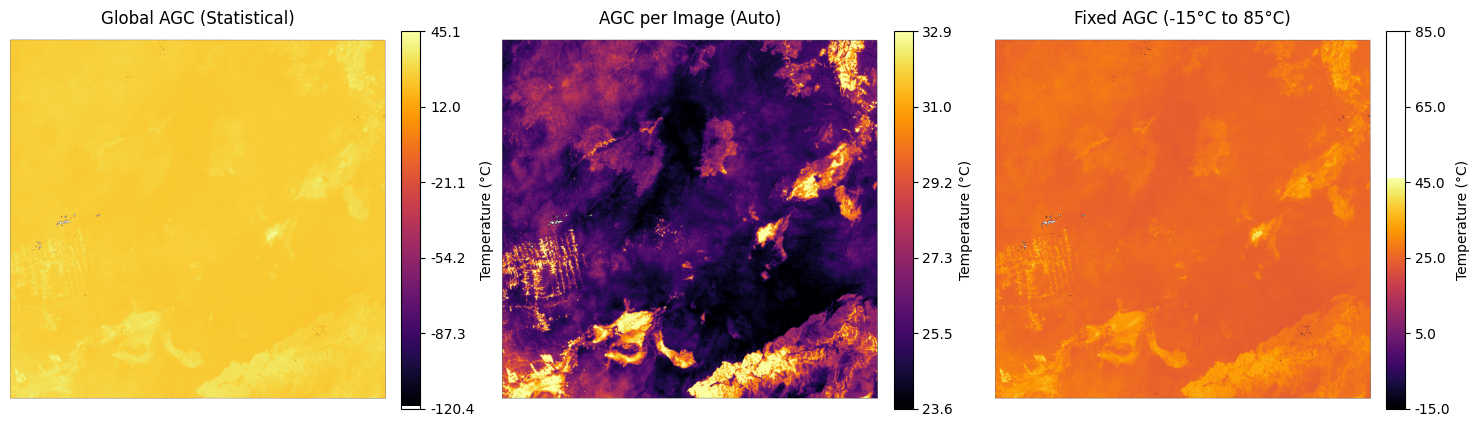

In [20]:
plt.figure(figsize=(18, 5))
ticks = np.linspace(0, 1, 6)

# Global AGC
plt.subplot(1, 3, 1)
im1 = plt.imshow(Tn_global, cmap="inferno")
plt.title("Global AGC (Statistical)")
plt.axis("off")
cbar1 = plt.colorbar(im1, fraction=0.046, pad=0.04)
labels = (T_low + ticks * (T_high - T_low)) - 273.15
cbar1.set_ticks(ticks)
cbar1.set_ticklabels([f"{t:.1f}" for t in labels])
cbar1.set_label("Temperature (°C)")

# ---- Auto ----
plt.subplot(1, 3, 2)
im2 = plt.imshow(Tn_auto, cmap="inferno")
plt.title("AGC per Image (Auto)")
plt.axis("off")
cbar2 = plt.colorbar(im2, fraction=0.046, pad=0.04)
labels = (Tli + ticks * (Thi - Tli)) - 273.15
cbar2.set_ticks(ticks)
cbar2.set_ticklabels([f"{t:.1f}" for t in labels])
cbar2.set_label("Temperature (°C)")

# ---- Fixed ----
plt.subplot(1, 3, 3)
im3 = plt.imshow(Tn_fixed, cmap="inferno")
plt.title("Fixed AGC (-15°C to 85°C)")
plt.axis("off")
cbar3 = plt.colorbar(im3, fraction=0.046, pad=0.04)
labels = (T_fixed_min + ticks * (T_fixed_max - T_fixed_min)) - 273.15
cbar3.set_ticks(ticks)
cbar3.set_ticklabels([f"{t:.1f}" for t in labels])
cbar3.set_label("Temperature (°C)")

plt.show()

## **Processing and Saving Batch of Images**

In [21]:
# Paths
BASE_DIR = "/content/drive/MyDrive/Dataset Wildfire/Pre-Processed_Images/Jul_Dec_2024"

DIRS = {
    "comparison": os.path.join(BASE_DIR, "comparison_plots"),

    "global_img": os.path.join(BASE_DIR, "agc_global/images"),
    "global_meta": os.path.join(BASE_DIR, "agc_global/metadata"),

    "auto_img": os.path.join(BASE_DIR, "agc_per_image/images"),
    "auto_meta": os.path.join(BASE_DIR, "agc_per_image/metadata"),

    "fixed_img": os.path.join(BASE_DIR, "agc_fixed/images"),
    "fixed_meta": os.path.join(BASE_DIR, "agc_fixed/metadata"),
}

for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

In [22]:
def save_metadata(path, data):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2)

def thermal_to_rgb(Tn, cmap="inferno"):
    cmap = plt.get_cmap(cmap)
    rgb = cmap(Tn)[..., :3]     # quitar canal alpha
    return (rgb * 255).astype(np.uint8)

In [23]:
def load_temperature(scene):
    square = preprocess_thermal_scene(scene["tif_path"])
    if square is None:
        return None
    return dn_to_temperature(square, scene["T_mult"], scene["T_add"])

In [24]:
def save_comparison_plot(scene, scene_id, T_low, T_high, out_path, cmap="inferno"):
    T = load_temperature(scene)
    if T is None:
        return

    # 1) Global
    Tn_global = apply_agc(T, T_low, T_high)

    # 2) Auto
    Tli, Thi = compute_percentiles(T, 2, 98)
    Tn_auto = apply_agc(T, Tli, Thi)

    # 3) Fixed
    T_fixed_min = -15.0 + 273.15
    T_fixed_max = 85.0 + 273.15
    Tn_fixed = apply_agc(T, T_fixed_min, T_fixed_max)

    # PLOT
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ticks = np.linspace(0, 1, 6)

    # --- Global ---
    im1 = axes[0].imshow(Tn_global, cmap=cmap)
    axes[0].set_title("Global AGC (Statistical)")
    axes[0].axis("off")
    cbar1 = fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)
    labels = (T_low + ticks * (T_high - T_low)) - 273.15
    cbar1.set_ticks(ticks)
    cbar1.set_ticklabels([f"{t:.1f}" for t in labels])
    cbar1.set_label("Temperature (°C)")

    # --- Auto ---
    im2 = axes[1].imshow(Tn_auto, cmap=cmap)
    axes[1].set_title("AGC per Image (Auto)")
    axes[1].axis("off")
    cbar2 = fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)
    labels = (Tli + ticks * (Thi - Tli)) - 273.15
    cbar2.set_ticks(ticks)
    cbar2.set_ticklabels([f"{t:.1f}" for t in labels])
    cbar2.set_label("Temperature (°C)")

    # --- Fixed ---
    im3 = axes[2].imshow(Tn_fixed, cmap=cmap)
    axes[2].set_title("Fixed AGC (-15°C to 85°C)")
    axes[2].axis("off")
    cbar3 = fig.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04)
    labels = (T_fixed_min + ticks * (T_fixed_max - T_fixed_min)) - 273.15
    cbar3.set_ticks(ticks)
    cbar3.set_ticklabels([f"{t:.1f}" for t in labels])
    cbar3.set_label("Temperature (°C)")

    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

In [25]:
def save_agc(scene, scene_id, mode, img_path, meta_path,
             T_low=None, T_high=None, cmap="inferno"):

    T = load_temperature(scene)
    if T is None:
        return

    if mode == "GLOBAL":
        Tmin, Tmax = T_low, T_high

    elif mode == "AUTO":
        Tmin, Tmax = compute_percentiles(T, 2, 98)

    elif mode == "FIXED":
        Tmin = -15.0 + 273.15
        Tmax = 85.0 + 273.15

    else:
        raise ValueError("Invalid AGC")

    Tn = apply_agc(T, Tmin, Tmax)
    rgb = thermal_to_rgb(Tn, cmap=cmap)

    plt.imsave(img_path, rgb)

    save_metadata(meta_path, {
        "scene_id": scene_id,
        "mode": f"AGC_{mode}",
        "T_min_K": float(Tmin),
        "T_max_K": float(Tmax),
        "T_min_C": float(Tmin - 273.15),
        "T_max_C": float(Tmax - 273.15),
    })

In [26]:
# Processing Images
for scene_id, scene in tqdm(scene_index.items(), desc="Saving Results"):
    save_comparison_plot(
        scene,
        scene_id,
        T_low,
        T_high,
        os.path.join(DIRS["comparison"], f"{scene_id}_comparison.png")
    )
    save_agc(
        scene,
        scene_id,
        mode="GLOBAL",
        T_low=T_low,
        T_high=T_high,
        img_path=os.path.join(DIRS["global_img"], f"{scene_id}_global.png"),
        meta_path=os.path.join(DIRS["global_meta"], f"{scene_id}_global.json"),
    )
    save_agc(
        scene,
        scene_id,
        mode="AUTO",
        img_path=os.path.join(DIRS["auto_img"], f"{scene_id}_auto.png"),
        meta_path=os.path.join(DIRS["auto_meta"], f"{scene_id}_auto.json"),
    )
    save_agc(
        scene,
        scene_id,
        mode="FIXED",
        img_path=os.path.join(DIRS["fixed_img"], f"{scene_id}_fixed.png"),
        meta_path=os.path.join(DIRS["fixed_meta"], f"{scene_id}_fixed.json"),
    )

Saving Results: 100%|██████████| 106/106 [25:25<00:00, 14.39s/it]
